Imports and Data Loading

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress warnings
import warnings
warnings.filterwarnings('ignore')

# Load the dataset safely
df = pd.read_csv('train.csv', sep=';', on_bad_lines='skip', quotechar='"')

# Clean column headers and target labels (strip hidden whitespaces)
df.columns = df.columns.str.strip()
df['medical_specialty'] = df['medical_specialty'].str.strip()

# Keep only the 12 valid classes specified in the project
valid_classes = df['medical_specialty'].value_counts()
valid_classes = valid_classes[valid_classes > 10].index.tolist()
df = df[df['medical_specialty'].isin(valid_classes)].copy()

print(f"Dataset loaded successfully. Shape: {df.shape}")
df.head(3)

Dataset loaded successfully. Shape: (2613, 5)


,medical_specialty,description,sample_name,transcription,keywords
0,Cardiovascular-Pulmonary,"Chest pain, possible syncopal spells. She ha...",Chest Pain - Cardiac Consult,"REASON FOR REFERRAL: Chest pain, possible syn...","cardiovascular / pulmonary, chest pain, syncop..."
1,Cardiovascular-Pulmonary,"The patient is 14 months old, comes in with a ...",Difficulty Breathing - ER Visit,"HISTORY: The patient is 14 months old, comes ...",NaN
2,Cardiovascular-Pulmonary,"Fiberoptic bronchoscopy, diagnostic. Hemopty...",Fiberoptic Bronchoscopy - 1,"PREOPERATIVE DIAGNOSIS:1. Hemoptysis.,2. His...","cardiovascular / pulmonary, hemoptysis, lung c..."


Analyzing Missing Values

In [5]:
# Calculate missing values
missing_data = df.isnull().sum().to_frame(name='Missing Count')
missing_data['Percentage (%)'] = (missing_data['Missing Count'] / len(df)) * 100

print("--- Missing Values Analysis ---")
display(missing_data.round(2))

--- Missing Values Analysis ---


,Missing Count,Percentage (%)
medical_specialty,0,0.00
description,0,0.00
sample_name,4,0.15
transcription,30,1.15
keywords,402,15.38


Class Imbalance

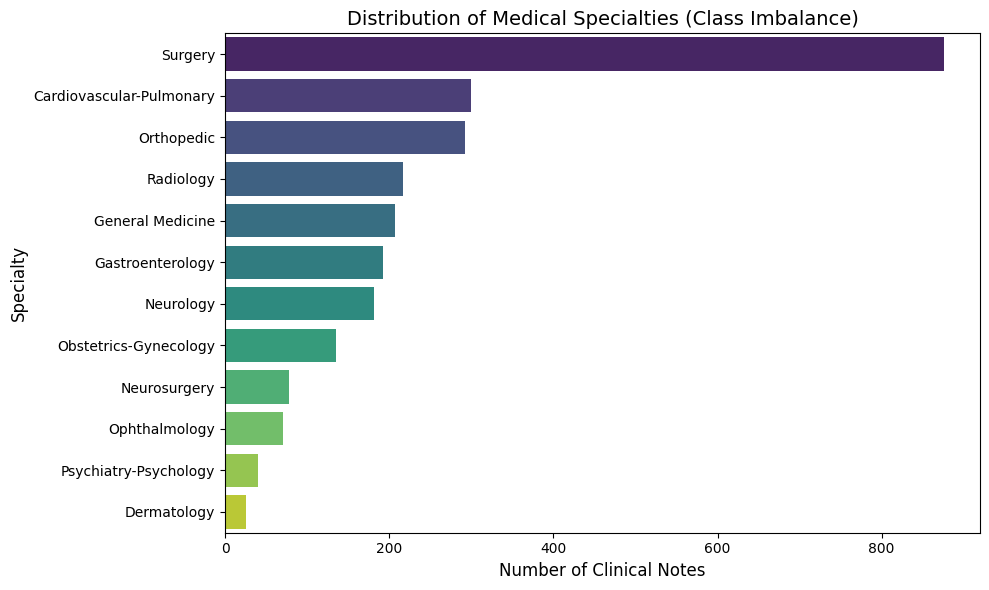

Minority Classes (High Risk for low F1-score):
medical_specialty
Neurosurgery             78
Ophthalmology            71
Psychiatry-Psychology    40
Dermatology              25
Name: count, dtype: int64


In [6]:
plt.figure(figsize=(10, 6))
sns.countplot(y='medical_specialty', data=df, order=df['medical_specialty'].value_counts().index, palette='viridis')
plt.title('Distribution of Medical Specialties (Class Imbalance)', fontsize=14)
plt.xlabel('Number of Clinical Notes', fontsize=12)
plt.ylabel('Specialty', fontsize=12)
plt.tight_layout()
plt.show()

# Print exact counts for the minority classes
print("Minority Classes (High Risk for low F1-score):")
print(df['medical_specialty'].value_counts().tail(4))

Text Length Analysis by Field

In [7]:
# Calculate word counts for each text column
for col in ['description', 'transcription', 'keywords']:
    # Fill NaNs with empty string temporarily just for counting
    df[f'{col}_word_count'] = df[col].fillna("").apply(lambda x: len(str(x).split()))

# Group by specialty to see average lengths
length_stats = df.groupby('medical_specialty')[['description_word_count', 'transcription_word_count']].mean().round(1)

print("--- Average Word Count by Specialty ---")
display(length_stats.sort_values(by='transcription_word_count', ascending=False))

--- Average Word Count by Specialty ---


,description_word_count,transcription_word_count
medical_specialty,,
Psychiatry-Psychology,15.6,823.7
Neurosurgery,84.3,572.4
Orthopedic,21.3,558.3
Neurology,16.6,499.2
Surgery,31.1,465.5
General Medicine,37.6,453.8
Obstetrics-Gynecology,51.4,440.0
Cardiovascular-Pulmonary,26.0,427.4
Dermatology,17.5,423.5


Visualizing Transcription Variance

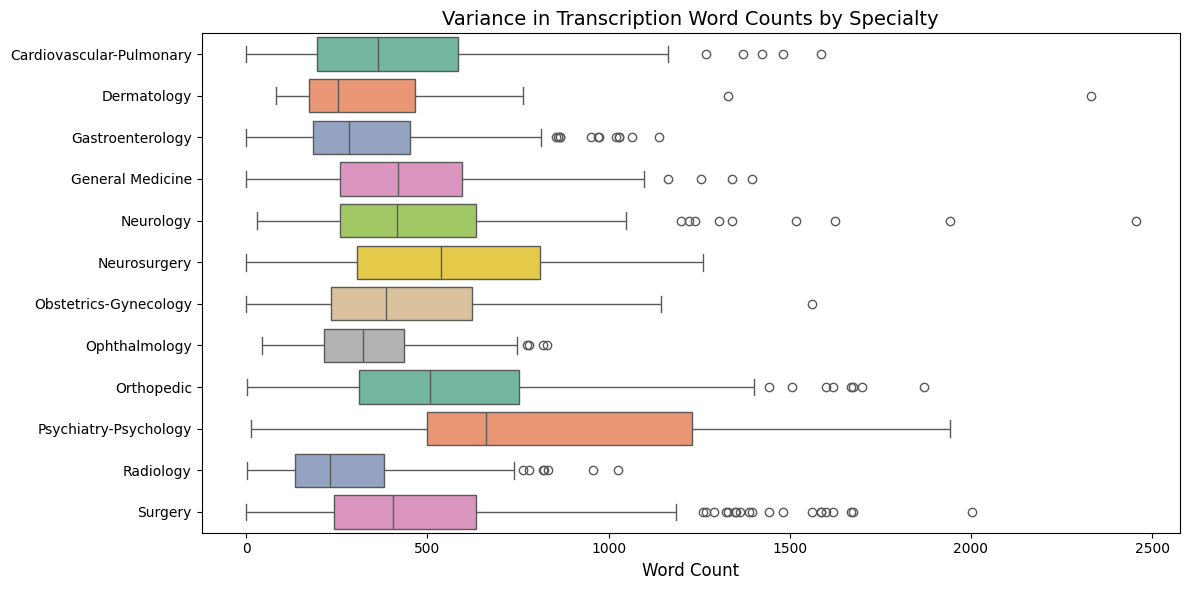

In [8]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='transcription_word_count', y='medical_specialty', data=df, palette='Set2')
plt.title('Variance in Transcription Word Counts by Specialty', fontsize=14)
plt.xlabel('Word Count', fontsize=12)
plt.ylabel('')
plt.tight_layout()
plt.show()

In [9]:
import pandas as pd

# 1. Load dataset with proper delimiter and quotation handling
df = pd.read_csv('train.csv', sep=';', on_bad_lines='skip', quotechar='"')

# 2. Clean column headers and target labels
df.columns = df.columns.str.strip()
df['medical_specialty'] = df['medical_specialty'].str.strip()

# 3. Filter valid 12 specialties (> 10 samples to eliminate parsing artifacts)
label_counts = df['medical_specialty'].value_counts()
useful_labels = label_counts[label_counts > 10]

# 4. Formatted summary print
print("=" * 55)
print("DISTRIBUTION OF USEFUL MEDICAL SPECIALTY LABELS")
print("=" * 55)
total_samples = useful_labels.sum()

for rank, (specialty, count) in enumerate(useful_labels.items(), start=1):
    pct = (count / total_samples) * 100
    print(f"{rank:2d}. {specialty:<26} : {count:>4} samples ({pct:>5.2f}%)")

print("-" * 55)
print(f"Total useful samples: {total_samples}")
print("=" * 55)

DISTRIBUTION OF USEFUL MEDICAL SPECIALTY LABELS
 1. Surgery                    :  876 samples (33.52%)
 2. Cardiovascular-Pulmonary   :  299 samples (11.44%)
 3. Orthopedic                 :  292 samples (11.17%)
 4. Radiology                  :  217 samples ( 8.30%)
 5. General Medicine           :  207 samples ( 7.92%)
 6. Gastroenterology           :  192 samples ( 7.35%)
 7. Neurology                  :  181 samples ( 6.93%)
 8. Obstetrics-Gynecology      :  135 samples ( 5.17%)
 9. Neurosurgery               :   78 samples ( 2.99%)
10. Ophthalmology              :   71 samples ( 2.72%)
11. Psychiatry-Psychology      :   40 samples ( 1.53%)
12. Dermatology                :   25 samples ( 0.96%)
-------------------------------------------------------
Total useful samples: 2613
